# Method, discount and final precision

**Three controlled questions about the same finite MDPs.**

1. At fixed discount and value-error target, how do VI-like, PI, MPI-like and
   linear-programming implementations compare?
2. At fixed final precision, what changes as the discount approaches one?
3. At fixed discount, what does tighter final precision cost?

The default experiment uses **one-factor-at-a-time sweeps**, not a full grid:
five discounts and four precision targets share one anchor. Three 100-state
MDPs and three repeats keep the demo small. Set `FULL_GRID=True` for a separate
experiment if you want to study discount × precision interactions.

The notebook opens saved results by default. Set `RUN_EXPERIMENTS=True` and
choose a **new, empty `STUDY_DIR`** to collect fresh measurements. Existing
trial data are never overwritten. Rendering saved figures needs
`python -m pip install -e ".[notebooks]"`; collecting the optional LP results
also needs the `gurobi` extra and a working Gurobi installation/license.
Use the repository root or `notebooks/` as the working directory.

In [1]:
import json
import random
from datetime import datetime, timezone
from importlib import import_module
from importlib.util import find_spec
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Run from the repository root or notebooks/")

RUN_EXPERIMENTS = False
STUDY_DIR = ROOT / "artifacts/results/solver_sensitivity"
FULL_GRID = False
INCLUDE_LP = True
REPEATS = 3
SEED = 0
MODEL_SEED = 0
THREADS = 1
TIMEOUT = None  # Small demo in-process; set a per-trial timeout for larger studies.
ANCHOR_DISCOUNT = 0.99
ANCHOR_PRECISION = 1e-3
DISCOUNTS = [0.5, 0.9, 0.95, 0.99, 0.995]
PRECISIONS = [1e-2, 1e-3, 1e-4, 1e-5]

MODEL_SPECS = [
    {
        "module": "garnet",
        "parameters": {"state_dim": 100, "action_dim": 5},
        "label": "Garnet",
    },
    {"module": "chain_walk", "parameters": {"state_dim": 100}, "label": "Chain Walk"},
    {"module": "rooms", "parameters": {"state_dim": 100}, "label": "Rooms"},
]
# Classification is explicit: solver_type alone does not describe every family.
SOLVER_SPECS = [
    {
        "module": "mdpforge_vi",
        "family": "VI-like",
        "label": "VI",
        "color": "#2563eb",
        "linestyle": "-",
        "marker": "o",
    },
    {
        "module": "aggregated_vi",
        "family": "VI-like",
        "label": "Aggregated VI",
        "color": "#4c8bbb",
        "linestyle": "--",
        "marker": "s",
    },
    {
        "module": "envelope_vi",
        "family": "VI-like",
        "label": "Envelope VI",
        "color": "#153d8a",
        "linestyle": ":",
        "marker": "^",
    },
    {
        "module": "mdpforge_pi",
        "family": "PI",
        "label": "PI · sparse evaluation",
        "color": "#008c87",
        "linestyle": "-",
        "marker": "D",
    },
    {
        "module": "mdpforge_mpi",
        "family": "MPI-like",
        "label": "MPI",
        "color": "#ce7611",
        "linestyle": "-",
        "marker": "o",
    },
    {
        "module": "aggregated_mpi",
        "family": "MPI-like",
        "label": "Aggregated MPI",
        "color": "#8a4b12",
        "linestyle": "--",
        "marker": "s",
    },
    {
        "module": "gurobi_primal",
        "family": "LP",
        "label": "LP primal · Gurobi",
        "dependency": "gurobipy",
        "color": "#875ac5",
        "linestyle": "-",
        "marker": "o",
    },
    {
        "module": "gurobi_dual",
        "family": "LP",
        "label": "LP dual · Gurobi",
        "dependency": "gurobipy",
        "color": "#533280",
        "linestyle": "--",
        "marker": "s",
    },
]

STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "#142c40",
    "axes.labelcolor": "#142c40",
    "xtick.color": "#526879",
    "ytick.color": "#526879",
    "axes.edgecolor": "#dae4ec",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "#f8fafc",
    "axes.facecolor": "white",
    "savefig.facecolor": "#f8fafc",
    "svg.fonttype": "none",
}

## Protocol and method choices

| Family | Implementations | What is being timed |
| --- | --- | --- |
| VI-like | VI, Aggregated VI, Envelope VI | Bellman updates, plus aggregation/precomputation where applicable |
| PI | mdpforge PI | Policy improvement and sparse linear-system policy evaluation |
| MPI-like (MPI / PIM) | MPI, Aggregated MPI | Policy improvement with truncated or aggregated evaluation |
| Linear programming | Gurobi primal and dual | LP model construction and solve; dual also recovers/evaluates a policy |

The LP **optimization formulation** is a separate family; solving a linear
system inside PI does not turn PI into an LP method. These are comparisons of
specific implementations, not universal rankings of algorithm families. LP uses
a different backend, so its effect cannot be separated from the implementation.

- Build each MDP once, from a fresh temporary cache, preserving native reward
  scales. Reuse its exact matrices throughout.
- Start every timed trial from a fresh solver and a copied model. No warm starts
  between discounts or precisions. Pair solver seeds `0`, `1`, `2`.
- Limit BLAS/OpenMP pools to one thread. The existing Gurobi factory also sets
  `Threads=1`. Solver options and stopping rules remain their defaults.
- Run one untimed-in-the-analysis anchor pass first; save it separately. Then
  randomize setting order with an independent RNG to reduce time/order drift.
- Runtime includes solver construction and execution; model generation,
  copying and independent accuracy checks are outside timing.
- Accept a trial only if the benchmark's **full Bellman residual** certifies
  $\|TV-V\|_\infty/(1-\gamma)\leq\varepsilon$. A median is drawn only when
  all three expected repeats passed. Min–max bands are observed spread, not
  confidence intervals. Keep every failed trial in the CSV and diagnostic table.

`final_precision` is a shared acceptance target, not necessarily an internal
tolerance. The current PI uses a sparse policy solve and the LP wrappers use
Gurobi's existing tolerances; neither tightens an iterative stopping rule when
you change this argument. They may oversolve or fail the tighter residual target.
The achieved-bound table makes this visible. No solver is modified for this study.

In [2]:
def collect_study():
    from mdpforge import Benchmark
    from mdpforge.utils import persistence

    if STUDY_DIR.exists():
        raise FileExistsError(
            "Choose a new, empty STUDY_DIR; saved experiments are preserved"
        )
    if ANCHOR_DISCOUNT not in DISCOUNTS or ANCHOR_PRECISION not in PRECISIONS:
        raise ValueError("Include the anchor in both sweep lists")
    if len(set(DISCOUNTS)) != len(DISCOUNTS) or len(set(PRECISIONS)) != len(PRECISIONS):
        raise ValueError("Sweep lists must not contain duplicates")
    if REPEATS < 1 or THREADS < 1:
        raise ValueError("Repeats and thread limits must be positive")
    if any(not np.isfinite(g) or not 0 < g < 1 for g in DISCOUNTS):
        raise ValueError("Discounts must be finite and in (0, 1)")
    if any(not np.isfinite(e) or e <= 0 for e in PRECISIONS):
        raise ValueError("Precision targets must be finite and positive")

    selected, omitted = [], []
    bench = Benchmark()
    for spec in SOLVER_SPECS:
        if spec["family"] == "LP" and not INCLUDE_LP:
            omitted.append(
                {"module": spec["module"], "reason": "LP explicitly disabled"}
            )
            continue
        dependency = spec.get("dependency")
        if dependency and find_spec(dependency) is None:
            omitted.append(
                {
                    "module": spec["module"],
                    "reason": f"Missing dependency: {dependency}",
                }
            )
            continue
        solver = import_module(f"mdpforge.solvers.{spec['module']}").Solver
        bench.add_solver(spec["module"], solve_function=solver)
        selected.append(spec)
    if not selected:
        raise ValueError("Select at least one solver")

    # A fresh cache avoids stale matrices with a matching recipe name.
    scratch = ROOT / "artifacts/tmp"
    scratch.mkdir(parents=True, exist_ok=True)
    old_cache = persistence.SAVED_MODELS_PATH
    numpy_state, random_state = np.random.get_state(), random.getstate()
    built_models = []
    try:
        with TemporaryDirectory(prefix="sensitivity-models-", dir=scratch) as directory:
            persistence.SAVED_MODELS_PATH = Path(directory)
            for recipe in MODEL_SPECS:
                np.random.seed(MODEL_SEED)
                random.seed(MODEL_SEED)
                model = import_module(f"mdpforge.models.{recipe['module']}").Model(
                    **recipe["parameters"]
                )
                model.create_model(cache="readonly")
                bench.add_mdp(model)
                built_models.append(
                    recipe
                    | {
                        "name": model.name,
                        "state_dim": model.state_dim,
                        "action_dim": model.action_dim,
                    }
                )
    finally:
        persistence.SAVED_MODELS_PATH = old_cache
        np.random.set_state(numpy_state)
        random.setstate(random_state)

    if FULL_GRID:
        settings = [(g, e) for g in DISCOUNTS for e in PRECISIONS]
    else:
        settings = list(
            dict.fromkeys(
                [(g, ANCHOR_PRECISION) for g in DISCOUNTS]
                + [(ANCHOR_DISCOUNT, e) for e in PRECISIONS]
            )
        )
    order = np.random.default_rng(SEED).permutation(len(settings))
    study = {
        "schema_version": 1,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "design": "full-grid" if FULL_GRID else "one-factor-at-a-time",
        "anchor": {"discount": ANCHOR_DISCOUNT, "precision": ANCHOR_PRECISION},
        "discounts": DISCOUNTS,
        "precisions": PRECISIONS,
        "repeats": REPEATS,
        "seed": SEED,
        "model_seed": MODEL_SEED,
        "threads": THREADS,
        "timeout": TIMEOUT,
        "models": built_models,
        "solvers": selected,
        "omitted_solvers": omitted,
        "runs": [],
    }
    STUDY_DIR.mkdir(parents=True)

    def save_index():
        (STUDY_DIR / "study.json").write_text(
            json.dumps(study, indent=2) + "\n", encoding="utf-8"
        )

    save_index()
    planned = len(settings) * len(built_models) * len(selected) * REPEATS
    print(
        f"Collecting {len(settings)} settings / {planned} timed-analysis trials, plus an excluded warmup pass",
        flush=True,
    )
    if omitted:
        print("Omitted solvers:", omitted, flush=True)
    with threadpool_limits(limits=THREADS):
        warmup = bench.run(
            discount=ANCHOR_DISCOUNT,
            precision=ANCHOR_PRECISION,
            repeats=1,
            seed=SEED,
            timeout=TIMEOUT,
        )
        warmup.export_csv(STUDY_DIR / "warmup.csv")
        study["warmup"] = {
            "file": "warmup.csv",
            "experiment_id": warmup.experiment["experiment_id"],
        }
        save_index()
        for position, index in enumerate(order):
            discount, precision = settings[index]
            print(
                f"[{position + 1}/{len(settings)}] γ={discount:g}, ε={precision:g}",
                flush=True,
            )
            result = bench.run(
                discount=discount,
                precision=precision,
                repeats=REPEATS,
                seed=SEED,
                timeout=TIMEOUT,
            )
            filename = f"setting_{position:02d}.csv"
            result.export_csv(STUDY_DIR / filename)
            study["runs"].append(
                {
                    "file": filename,
                    "experiment_id": result.experiment["experiment_id"],
                    "discount": discount,
                    "precision": precision,
                }
            )
            save_index()
            print(
                pd.Series([row["status"] for row in result.rows])
                .value_counts()
                .to_dict(),
                flush=True,
            )
    study["complete"] = True
    save_index()
    return study


if RUN_EXPERIMENTS:
    collect_study()
else:
    print(
        "Reading saved study. Set RUN_EXPERIMENTS=True and choose a new STUDY_DIR to measure again."
    )

Reading saved study. Set RUN_EXPERIMENTS=True and choose a new STUDY_DIR to measure again.


## Load and verify the saved comparisons

The saved study index supplies the actual configuration, so editing collection
parameters above never relabels old data. Each setting keeps its original CSV
and `*.experiment.json` from `BenchmarkResult.export_csv()`. The loader checks settings,
trial seeds, candidate sets, model configurations, versions and thread pools across
runs. Partially collected studies are rejected; raw progress files remain available.

In [3]:
def load_study(directory):
    study = json.loads((directory / "study.json").read_text(encoding="utf-8"))
    if not study.get("complete"):
        raise ValueError(
            "Study is incomplete; inspect saved CSVs before starting a fresh study"
        )
    model_names = {m["name"] for m in study["models"]}
    solver_names = {s["module"] for s in study["solvers"]}
    expected_trials = len(model_names) * len(solver_names) * study["repeats"]
    model_metadata, environment, solver_metadata = None, None, None
    frames, manifests = [], []
    observed_settings = set()
    for run in study["runs"]:
        path = directory / run["file"]
        frame = pd.read_csv(path)
        manifest = json.loads(
            path.with_suffix(".experiment.json").read_text(encoding="utf-8")
        )
        if manifest["experiment_id"] != run["experiment_id"] or set(
            frame.experiment_id
        ) != {run["experiment_id"]}:
            raise ValueError("Mismatched experiment identities")
        if (
            len(frame) != expected_trials
            or frame.duplicated(["model", "solver", "repeat"]).any()
        ):
            raise ValueError("Missing or duplicated trials")
        if set(frame.model) != model_names or set(frame.solver) != solver_names:
            raise ValueError("Candidate sets changed within the study")
        if set(frame.discount) != {run["discount"]} or set(frame.epsilon) != {
            run["precision"]
        }:
            raise ValueError("CSV settings do not match the study index")
        settings = manifest["settings"]
        if (
            settings["discount"] != run["discount"]
            or settings["precision"] != run["precision"]
        ):
            raise ValueError("Manifest settings do not match the study index")
        if (
            settings["repeats"] != study["repeats"]
            or settings["seed"] != study["seed"]
            or settings["timeout"] != study["timeout"]
        ):
            raise ValueError("Execution settings changed")
        for _, trials in frame.groupby(["model", "solver"], sort=False):
            if set(trials.repeat) != set(range(1, study["repeats"] + 1)):
                raise ValueError("Repeat sets changed")
            if not trials.seed.eq(study["seed"] + trials.repeat - 1).all():
                raise ValueError("Trial seeds changed")
        current = {
            name: {
                field: model[field]
                for field in ("class", "state_dim", "action_dim", "config")
            }
            for name, model in manifest["models"].items()
        }
        if set(current) != model_names or (
            model_metadata is not None and current != model_metadata
        ):
            raise ValueError("Model configurations changed across settings")
        model_metadata = current
        if environment is not None and manifest["environment"] != environment:
            raise ValueError("Package versions changed across settings")
        environment = manifest["environment"]
        if solver_metadata is not None and manifest["solvers"] != solver_metadata:
            raise ValueError("Solver implementations or constructor options changed")
        solver_metadata = manifest["solvers"]
        if any(
            pool["num_threads"] != study["threads"]
            for pool in manifest["machine"]["thread_pools"]
        ):
            raise ValueError("Recorded thread pools do not match the planned limit")
        passed = frame.status.eq("success")
        certified = (
            np.isfinite(frame.runtime)
            & frame.runtime.gt(0)
            & np.isfinite(frame.error_bound)
            & frame.error_bound.ge(0)
            & frame.error_bound.le(frame.epsilon)
        )
        if (passed & ~certified).any():
            raise ValueError("A success row does not meet its precision target")
        setting = (run["discount"], run["precision"])
        if setting in observed_settings:
            raise ValueError("Duplicate settings would pool independent runs")
        observed_settings.add(setting)
        frames.append(frame)
        manifests.append(manifest)
    planned = (
        {(g, e) for g in study["discounts"] for e in study["precisions"]}
        if study["design"] == "full-grid"
        else {(g, study["anchor"]["precision"]) for g in study["discounts"]}
        | {(study["anchor"]["discount"], e) for e in study["precisions"]}
    )
    if observed_settings != planned:
        raise ValueError("Study does not contain every planned setting")
    return study, pd.concat(frames, ignore_index=True), manifests


study, trials, manifests = load_study(STUDY_DIR)
specs = {s["module"]: s for s in study["solvers"]}
models = study["models"]
anchor = study["anchor"]

print("Collected:", study["created_at_utc"])
print(
    "Design:",
    study["design"],
    "· threads:",
    study["threads"],
    "· trial repeats:",
    study["repeats"],
)
print("Trials:", len(trials), "· statuses:", trials.status.value_counts().to_dict())
print("Backend versions:", manifests[0]["environment"]["backends"])
print("Omitted solvers:", study["omitted_solvers"])
display(pd.DataFrame(study["solvers"])[["module", "family", "label"]])

keys = ["model", "solver", "discount", "epsilon"]
summary = (
    trials.groupby(keys, sort=False)
    .agg(
        median_s=("runtime", "median"),
        min_s=("runtime", "min"),
        max_s=("runtime", "max"),
        trials=("status", "size"),
        passed=("status", lambda x: x.eq("success").sum()),
        worst_bound=("error_bound", "max"),
    )
    .reset_index()
)
summary["eligible"] = summary.trials.eq(study["repeats"]) & summary.passed.eq(
    study["repeats"]
)
summary.loc[~summary.eligible, ["median_s", "min_s", "max_s"]] = np.nan
summary["bound_over_target"] = summary.worst_bound / summary.epsilon

Collected: 2026-10-13T10:29:57.879141+00:00
Design: one-factor-at-a-time · threads: 1 · trial repeats: 3
Trials: 576 · statuses: {'success': 576}
Backend versions: {'gurobipy': {'distribution': 'gurobipy', 'version': '13.0.1'}}
Omitted solvers: []


,module,family,label
0,mdpforge_vi,VI-like,VI
1,aggregated_vi,VI-like,Aggregated VI
2,envelope_vi,VI-like,Envelope VI
3,mdpforge_pi,PI,PI · sparse evaluation
4,mdpforge_mpi,MPI-like,MPI
5,aggregated_mpi,MPI-like,Aggregated MPI
6,gurobi_primal,LP,LP primal · Gurobi
7,gurobi_dual,LP,LP dual · Gurobi


## 1. Influence of the method at the shared anchor

The anchor is $\gamma=0.99$, $\varepsilon=10^{-3}$ in the saved demo. Colours
group methods; each row still names the actual implementation. Dots show median
runtimes and bars show min–max across repeats. The comparison includes setup
costs, which can dominate on small MDPs. `FAIL` means at least one repeat failed
the independent acceptance test; successful subsets are not ranked.

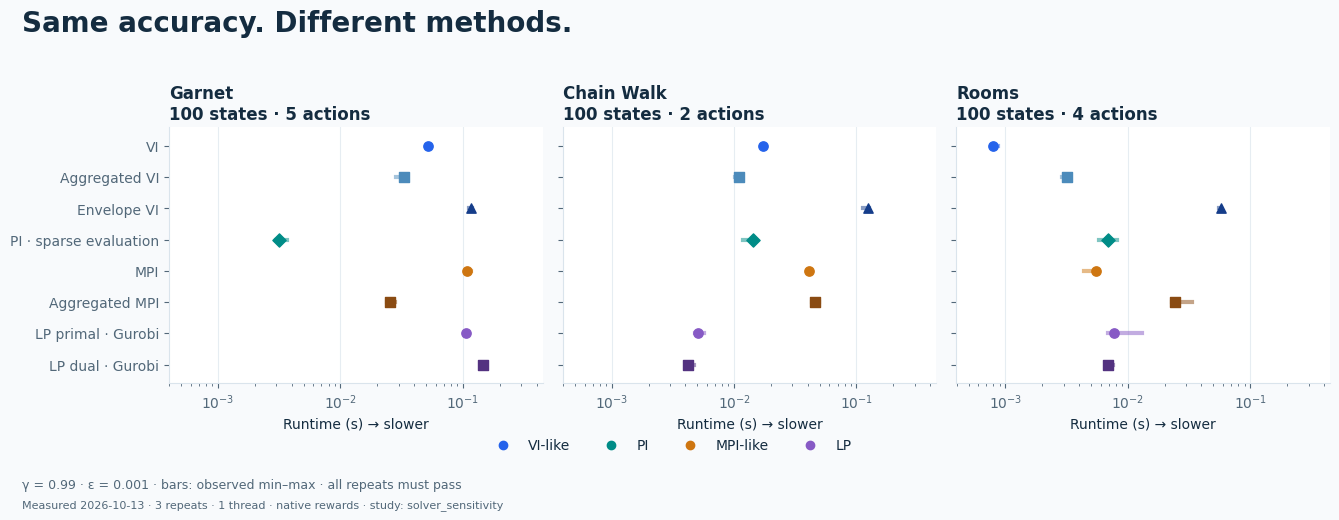

In [4]:
def export_plot(fig, name):
    # Keep a fresh study's figures separate from the versioned demo figures.
    is_demo = (
        STUDY_DIR.resolve() == (ROOT / "artifacts/results/solver_sensitivity").resolve()
    )
    output = ROOT / "artifacts/figures" if is_demo else STUDY_DIR / "figures"
    output.mkdir(parents=True, exist_ok=True)
    bottom = min([0.0] + [t.get_position()[1] for t in fig.texts])
    fig.text(
        0.02,
        bottom - 0.045,
        f"Measured {study['created_at_utc'][:10]} · {study['repeats']} repeats · {study['threads']} thread · native rewards · study: {STUDY_DIR.name}",
        color="#526879",
        fontsize=8,
    )
    for extension in ("png", "svg"):
        fig.savefig(output / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def plot_methods():
    selected = summary.loc[
        summary.discount.eq(anchor["discount"])
        & summary.epsilon.eq(anchor["precision"])
    ]
    finite = selected.loc[selected.eligible]
    if finite.empty:
        raise ValueError("No eligible anchor runtimes")
    lower, upper = finite.min_s.min() / 2, finite.max_s.max() * 3
    order = list(specs)
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            1,
            len(models),
            figsize=(4.5 * len(models), max(4.2, 0.35 * len(order) + 1.4)),
            sharey=True,
            squeeze=False,
        )
        for ax, model in zip(axes[0], models):
            rows = selected.loc[selected.model.eq(model["name"])].set_index("solver")
            for position, solver in enumerate(order):
                y = len(order) - 1 - position
                row, spec = rows.loc[solver], specs[solver]
                if not row.eligible:
                    ax.text(
                        0.03,
                        y,
                        "FAIL",
                        transform=ax.get_yaxis_transform(),
                        color="#b44242",
                        fontsize=9,
                    )
                    continue
                ax.plot(
                    [row.min_s, row.max_s],
                    [y, y],
                    color=spec["color"],
                    linewidth=3,
                    alpha=0.5,
                )
                ax.scatter(
                    [row.median_s],
                    [y],
                    color=spec["color"],
                    marker=spec["marker"],
                    s=45,
                    zorder=3,
                )
            ax.set_yticks(
                range(len(order)), [specs[s]["label"] for s in reversed(order)]
            )
            ax.set_ylim(-0.6, len(order) - 0.4)
            ax.set_xscale("log")
            ax.set_xlim(lower, upper)
            ax.grid(axis="x", color="#dae4ec", alpha=0.65)
            ax.set_axisbelow(True)
            ax.set_title(
                f"{model['label']}\n{model['state_dim']} states · {model['action_dim']} actions",
                loc="left",
                fontweight="bold",
                fontsize=12,
            )
            ax.set_xlabel("Runtime (s) → slower")
        fig.suptitle(
            "Same accuracy. Different methods.",
            x=0.02,
            ha="left",
            fontsize=20,
            fontweight="bold",
            y=1.04,
        )
        family_colors = {
            "VI-like": "#2563eb",
            "PI": "#008c87",
            "MPI-like": "#ce7611",
            "LP": "#875ac5",
        }
        handles = [
            plt.Line2D([], [], marker="o", linestyle="none", color=color, label=family)
            for family, color in family_colors.items()
            if any(s["family"] == family for s in specs.values())
        ]
        fig.legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.045),
            ncol=4,
            frameon=False,
        )
        fig.text(
            0.02,
            -0.10,
            f"γ = {anchor['discount']:g} · ε = {anchor['precision']:g} · bars: observed min–max · all repeats must pass",
            color="#526879",
            fontsize=9,
        )
        fig.tight_layout()
    return fig


export_plot(plot_methods(), "sensitivity_methods")

## 2–3. Influence of discount and final precision

Top row: vary only discount, holding the anchor precision fixed. The axis uses
logarithmic spacing in $1/(1-\gamma)$ to separate discounts near one, and labels
the actual $\gamma$. Higher discount changes the optimal-control problem itself;
the matrices and rewards stay fixed, not the optimal values or policies.

Bottom row: vary only the requested absolute value-error target at the anchor
discount. The precision axis tightens from left to right. Median lines and
min–max bands include only fully successful groups; a failed repeat breaks the
line. Crosses along the bottom locate failures, coloured by implementation.
No runtime is invented for a failed group. Vertical dashed lines mark the anchor.

Both parameters enter the acceptance threshold
$\|TV-V\|_\infty\leq\varepsilon(1-\gamma)$: increasing discount tightens this
residual requirement even when absolute value precision is held fixed. These
two sweeps alone do not identify their interaction.

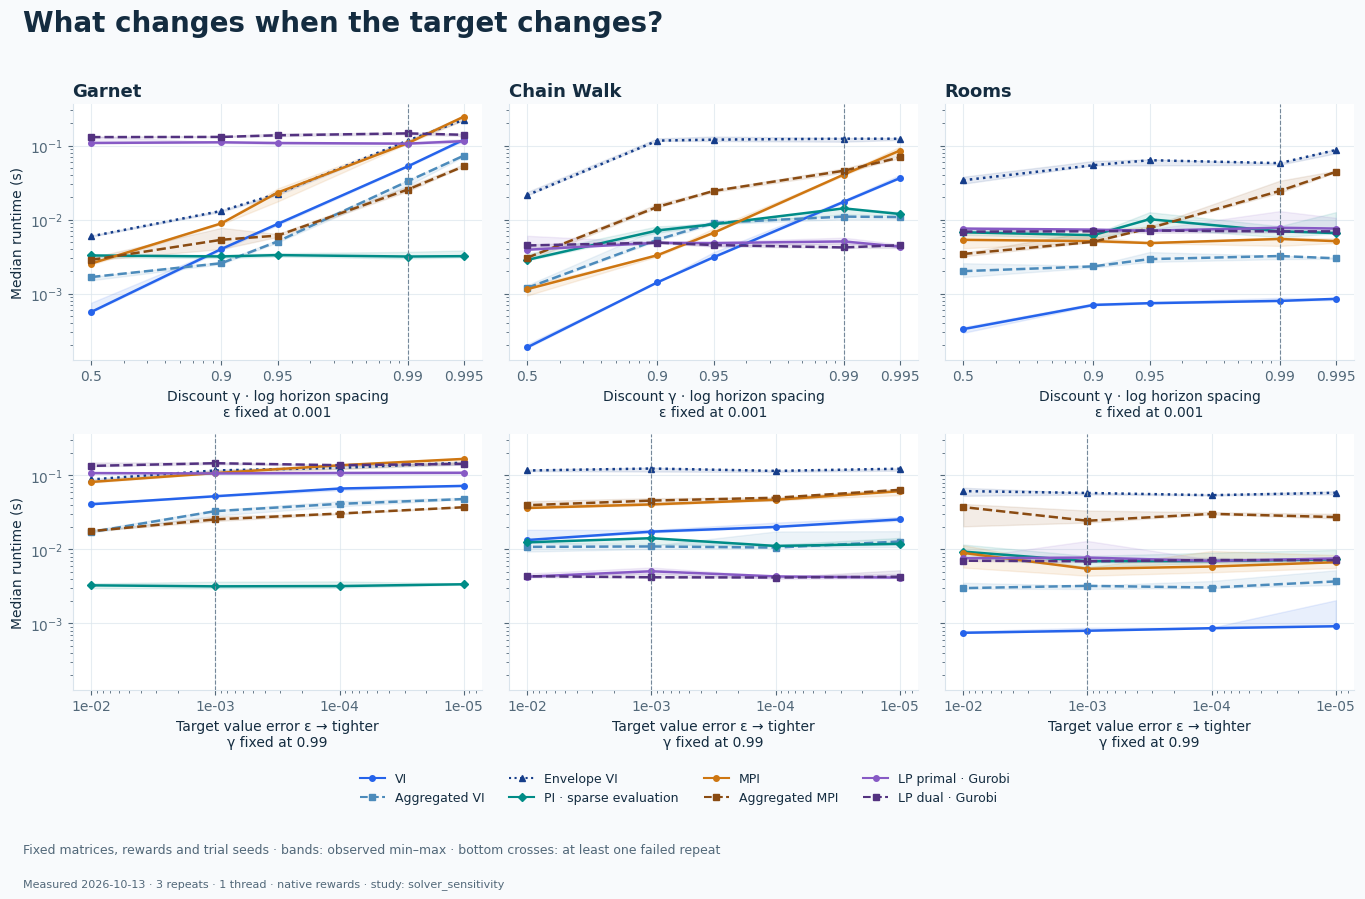

In [5]:
def draw_sweep(ax, model, parameter, solver_selection):
    if parameter == "discount":
        rows = summary.loc[
            summary.model.eq(model["name"]) & summary.epsilon.eq(anchor["precision"])
        ]
        grid = np.array(sorted(study["discounts"]))
        x = 1 / (1 - grid)
        baseline = 1 / (1 - anchor["discount"])
    else:
        rows = summary.loc[
            summary.model.eq(model["name"]) & summary.discount.eq(anchor["discount"])
        ]
        grid = np.array(sorted(study["precisions"]))
        x, baseline = grid, anchor["precision"]
    for index, solver in enumerate(solver_selection):
        spec = specs[solver]
        values = rows.loc[rows.solver.eq(solver)].set_index(parameter).reindex(grid)
        ax.plot(
            x,
            values.median_s,
            color=spec["color"],
            linestyle=spec["linestyle"],
            marker=spec["marker"],
            markersize=4,
            linewidth=1.8,
        )
        ax.fill_between(
            x,
            values.min_s.to_numpy(),
            values.max_s.to_numpy(),
            color=spec["color"],
            alpha=0.10,
        )
        failed = ~values.eligible.to_numpy(dtype=bool)
        if failed.any():
            ax.scatter(
                x[failed],
                np.full(failed.sum(), 0.025 + index * 0.035),
                transform=ax.get_xaxis_transform(),
                marker="x",
                color=spec["color"],
                s=27,
                zorder=4,
            )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(baseline, color="#75889a", linestyle="--", linewidth=0.8)
    ax.grid(color="#dae4ec", alpha=0.65)
    ax.set_axisbelow(True)
    ax.set_xticks(x)
    if parameter == "discount":
        ax.set_xticklabels([f"{g:g}" for g in grid])
        ax.set_xlabel(
            f"Discount γ · log horizon spacing\nε fixed at {anchor['precision']:g}"
        )
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda e, _: f"{e:.0e}"))
        ax.invert_xaxis()
        ax.set_xlabel(
            f"Target value error ε → tighter\nγ fixed at {anchor['discount']:g}"
        )


def solver_handles(selection):
    return [
        plt.Line2D(
            [],
            [],
            color=specs[s]["color"],
            linestyle=specs[s]["linestyle"],
            marker=specs[s]["marker"],
            markersize=4,
            label=specs[s]["label"],
        )
        for s in selection
    ]


def plot_sweeps():
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            2, len(models), figsize=(4.6 * len(models), 7.4), sharey=True, squeeze=False
        )
        for column, model in enumerate(models):
            for row_index, parameter in enumerate(("discount", "epsilon")):
                ax = axes[row_index, column]
                draw_sweep(ax, model, parameter, list(specs))
                if row_index == 0:
                    ax.set_title(
                        model["label"], loc="left", fontweight="bold", fontsize=13
                    )
                if column == 0:
                    ax.set_ylabel("Median runtime (s)")
        handles = solver_handles(list(specs))
        fig.legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.07),
            ncol=4,
            frameon=False,
            fontsize=9,
        )
        fig.suptitle(
            "What changes when the target changes?",
            x=0.02,
            ha="left",
            fontsize=20,
            fontweight="bold",
            y=1.02,
        )
        fig.text(
            0.02,
            -0.12,
            "Fixed matrices, rewards and trial seeds · bands: observed min–max · bottom crosses: at least one failed repeat",
            fontsize=9,
            color="#526879",
        )
        fig.tight_layout()
    return fig


export_plot(plot_sweeps(), "sensitivity_sweeps")

### Compact README view

The README example intentionally selects the saved Garnet instance and one
implementation from each available family: plain VI, sparse-evaluation PI,
plain MPI and primal LP. This is a documented illustration, not a family
aggregate or a selection based on which solver won. The complete plots above
retain all implementations and all models. Edit these selections for another
case study without collecting new timings.

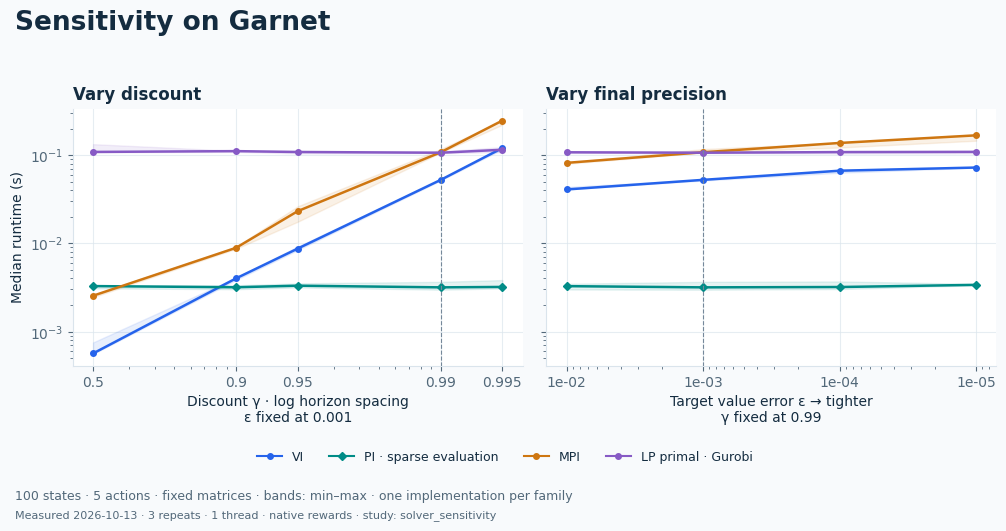

In [6]:
README_MODEL = models[0]
README_SOLVERS = [
    s
    for s in ("mdpforge_vi", "mdpforge_pi", "mdpforge_mpi", "gurobi_primal")
    if s in specs
]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1), sharey=True)
    for ax, parameter, title in zip(
        axes, ("discount", "epsilon"), ("Vary discount", "Vary final precision")
    ):
        draw_sweep(ax, README_MODEL, parameter, README_SOLVERS)
        ax.set_title(title, loc="left", fontweight="bold", fontsize=12)
    axes[0].set_ylabel("Median runtime (s)")
    fig.legend(
        handles=solver_handles(README_SOLVERS),
        loc="lower center",
        bbox_to_anchor=(0.5, -0.085),
        ncol=4,
        frameon=False,
        fontsize=9,
    )
    fig.suptitle(
        f"Sensitivity on {README_MODEL['label']}",
        x=0.02,
        ha="left",
        fontsize=19,
        fontweight="bold",
        y=1.05,
    )
    fig.text(
        0.02,
        -0.145,
        f"{README_MODEL['state_dim']} states · {README_MODEL['action_dim']} actions · fixed matrices · bands: min–max · one implementation per family",
        fontsize=9,
        color="#526879",
    )
    fig.tight_layout()
export_plot(fig, "readme_sensitivity")

## Achieved precision and failures

These tables keep quality visible. A value of 0.01 in the bound/target table
means the reported bound is 100 times tighter than requested; it does not
measure actual error. Failed groups retain their worst observed bound but are
excluded from runtime plots. For a failed trial with no returned value the
bound is missing, so inspect its error message.

The normalized table divides each median by the same solver/model's anchor
median. It measures **sensitivity**, not a speedup against a different algorithm.
A missing or failed anchor produces no normalized ratio.

In [7]:
precision_rows = summary.loc[summary.discount.eq(anchor["discount"])].copy()
precision_rows["method"] = precision_rows.solver.map(lambda s: specs[s]["label"])
bound_table = precision_rows.pivot(
    index=["model", "method"], columns="epsilon", values="bound_over_target"
)
display(bound_table.style.format("{:.2e}", na_rep="no bound"))

baseline_rows = summary.loc[
    summary.discount.eq(anchor["discount"]) & summary.epsilon.eq(anchor["precision"])
]
baseline = baseline_rows[["model", "solver", "median_s"]].rename(
    columns={"median_s": "anchor_s"}
)
relative = summary.merge(baseline, on=["model", "solver"], validate="many_to_one")
relative["runtime_over_anchor"] = relative.median_s / relative.anchor_s
display(
    relative[
        [
            "model",
            "solver",
            "discount",
            "epsilon",
            "passed",
            "trials",
            "runtime_over_anchor",
        ]
    ].round({"runtime_over_anchor": 3})
)

failures = trials.loc[
    trials.status.ne("success"),
    [
        "model",
        "solver",
        "discount",
        "epsilon",
        "repeat",
        "status",
        "error_bound",
        "error",
    ],
]
print(f"Failed trials retained: {len(failures)} / {len(trials)}")
if not failures.empty:
    display(failures)

# Summary exports do not replace the per-setting CSVs or experiment manifests.
summary.to_csv(STUDY_DIR / "summary.csv", index=False)
relative.to_csv(STUDY_DIR / "sensitivity.csv", index=False)

Failed trials retained: 0 / 576


,model,solver,discount,epsilon,passed,trials,runtime_over_anchor
0,100_5_garnet_0.85_1.0,mdpforge_vi,0.95,0.00100,3,3,0.166
1,100_5_garnet_0.85_1.0,aggregated_vi,0.95,0.00100,3,3,0.153
2,100_5_garnet_0.85_1.0,envelope_vi,0.95,0.00100,3,3,0.192
3,100_5_garnet_0.85_1.0,mdpforge_pi,0.95,0.00100,3,3,1.044
4,100_5_garnet_0.85_1.0,mdpforge_mpi,0.95,0.00100,3,3,0.215
...,...,...,...,...,...,...,...
187,100_4_rooms,mdpforge_pi,0.99,0.00001,3,3,1.059
188,100_4_rooms,mdpforge_mpi,0.99,0.00001,3,3,1.228
189,100_4_rooms,aggregated_mpi,0.99,0.00001,3,3,1.121
190,100_4_rooms,gurobi_primal,0.99,0.00001,3,3,0.973


## Interpretation and next experiments

- Read each model separately. A pooled average of seconds over unrelated MDPs
  would confound model structure with method. There is one generated instance
  per model family; the three solver repeats do not measure model-generation
  variability. Small-instance results are not scalability evidence.
- Family colours are an aid to reading, not a controlled causal estimate of a
  family effect. Implementations, aggregation settings and the LP backend differ.
  Add several implementations per family and multiple model-generation seeds
  before drawing broad conclusions.
- The full-residual certificate is conservative. PI/LP may oversolve, and a
  high-discount LP can miss a tight target under unchanged numerical tolerances.
  Keep that outcome instead of relaxing the acceptance rule.
- Setting order is randomized; solver order is fixed. Short runtimes and only
  three repeats can be noisy. For a publication study, increase repeats and
  vary solver order with recorded provenance.
- To study discount × precision interactions, collect a **new full-grid study**
  (`FULL_GRID=True`) and inspect both sweeps for several slices. The default
  figures deliberately use the anchor slices of either design.
- Larger state spaces, different reward scales and convergence traces are
  separate experiments. Do not regenerate matrices between sweep settings or
  reuse an optimal-value cache after changing model parameters.

The CSVs and manifests in `artifacts/results/solver_sensitivity/` reproduce the
saved demo plots without running solvers. Use the
[visual gallery](visualize_results.ipynb) for performance profiles and outcome
plots on a single fixed-setting export from this study.